In [163]:
import warnings
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pymfe.mfe import MFE
from scipy.io import arff
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from tqdm import tqdm


In [164]:
MAX_OBSERVATIONS = 5000
MAX_FEATURES = 100


dataset_paths = sorted(Path("data").glob("*.arff"))

cols_with_target, chosen_dataset = [], []
for path in tqdm(dataset_paths):
    try:
        data, meta = arff.loadarff(path)
        df = pd.DataFrame(data)

        if len(df) > MAX_OBSERVATIONS:
            print(f"Пропускаем {path} из-за длины = {len(df)}")
            continue
        if len(df.columns) > MAX_FEATURES:
            print(f"Пропускаем {path} из-за кол-ва признаков = {len(df.columns)}")
            continue

        maybe_with_class = df.filter(regex="class|Class|target|Target")
        if not maybe_with_class.empty and meta[maybe_with_class.columns[0]][0] == "nominal":
            cols_with_target.append(maybe_with_class.columns[0])
            chosen_dataset.append(path)
        del df
    except:  
        continue
   

 16%|█▋        | 122/744 [00:00<00:02, 230.20it/s]

Пропускаем data/1460.arff из-за длины = 5300
Пропускаем data/1525.arff из-за длины = 5456
Пропускаем data/1526.arff из-за длины = 5456
Пропускаем data/1531.arff из-за длины = 10176
Пропускаем data/1532.arff из-за длины = 10668
Пропускаем data/1533.arff из-за длины = 10386
Пропускаем data/1534.arff из-за длины = 10190
Пропускаем data/1535.arff из-за длины = 9989
Пропускаем data/1536.arff из-за длины = 10130


 20%|█▉        | 146/744 [00:01<00:05, 101.26it/s]

Пропускаем data/1538.arff из-за длины = 8753
Пропускаем data/1539.arff из-за длины = 9172
Пропускаем data/1540.arff из-за длины = 9285
Пропускаем data/1541.arff из-за длины = 8654


 25%|██▍       | 183/744 [00:01<00:04, 123.29it/s]

...

 88%|████████▊ | 658/744 [00:03<00:00, 327.81it/s]

Пропускаем data/828.arff из-за кол-ва признаков = 101


 97%|█████████▋| 722/744 [00:03<00:00, 276.10it/s]

Пропускаем data/923.arff из-за длины = 8641


100%|██████████| 744/744 [00:03<00:00, 218.10it/s]


In [165]:
def prepare_dataset(dataset_path: str, target_column: str) -> tuple[pd.DataFrame, np.ndarray]:
    data, _ = arff.loadarff(dataset_path)

    df = pd.DataFrame(data)
    for column in df.select_dtypes(include="object").columns:
        df[column] = df[column].str.decode("utf-8")

    X = df.drop(target_column, axis=1)
    y = LabelEncoder().fit_transform(df[target_column])

    return X, y

In [166]:
x, y = prepare_dataset(chosen_dataset[5], cols_with_target[5])

### Функции для выделения ручных метафичей

In [167]:
def size_features(x: pd.DataFrame, y: np.ndarray) -> dict[str, float]:
    n, p = x.shape

    return {
        "n_obs": float(n),
        "n_features": float(p),
        "features_to_obs": float(p / n) if n else np.nan,
    }


def distribution_features(x: pd.DataFrame, y: np.ndarray) -> dict[str, float]:
    numeric = x.select_dtypes(include="number")
    categorical = x.drop(columns=numeric.columns)

    cardinalities = x.nunique(dropna=False)
    relative = cardinalities / len(x)

    entropies = categorical.apply(
        lambda col: -(p := col.value_counts(normalize=True, dropna=False))
        .mul(np.log2(p))
        .sum()
    )

    result = {
        "constant_features_ratio": float((cardinalities <= 1).mean()),
        "binary_features_ratio": float((cardinalities == 2).mean()),
        "cardinality_mean": float(cardinalities.mean()),
        "cardinality_std": float(cardinalities.std(ddof=0)),
        "relative_cardinality_mean": float(relative.mean()),
        "relative_cardinality_std": float(relative.std(ddof=0)),
        "high_uniqueness_ratio": float((relative > 0.95).mean()),
        "categorical_features_ratio": float(categorical.shape[1] / x.shape[1]),
        "categorical_entropy_mean": float(entropies.mean()),
        "categorical_entropy_std": float(entropies.std(ddof=0)),
    }

    if numeric.shape[1]:
        scaled = StandardScaler().fit_transform(numeric)
        zeros = np.isclose(scaled, 0).mean(axis=0)

        result.update({
            "zero_ratio": float(zeros.mean()),
            "zero_ratio_std": float(zeros.std()),
            "zero_ratio_max": float(zeros.max()),
        })

    return result


def class_features(x: pd.DataFrame, y: np.ndarray) -> dict[str, float]:
    rates = pd.Series(np.asarray(y).ravel()).value_counts(normalize=True)

    return {
        "n_classes": float(len(rates)),
        "class_rate_min": float(rates.min()),
        "class_rate_max": float(rates.max()),
        "class_rate_std": float(rates.std(ddof=0)),
        "class_entropy": float(-(rates * np.log2(rates)).sum()),
    }


def statistical_features(x: pd.DataFrame, y: np.ndarray) -> dict[str, float]:
    numeric = x.select_dtypes(include="number")

    if numeric.shape[1] == 0:
        return {}

    data = pd.DataFrame(
        StandardScaler().fit_transform(numeric),
        columns=numeric.columns,
    )

    data = data.loc[:, data.std(ddof=0) > 0]

    if data.shape[1] == 0:
        return {}

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    outliers = (
        data.lt(q1 - 1.5 * iqr) |
        data.gt(q3 + 1.5 * iqr)
    ).sum() / data.count()

    median = data.median().abs()
    ranges = data.max() - data.min()
    skewness = data.skew().abs()
    kurt = data.kurt()

    result = {
        "median_abs_mean": float(median.mean()),
        "median_abs_max": float(median.max()),
        "iqr_mean": float(iqr.mean()),
        "iqr_std": float(iqr.std(ddof=0)),
        "range_mean": float(ranges.mean()),
        "range_max": float(ranges.max()),
        "skewness_abs_mean": float(skewness.mean()),
        "skewness_abs_std": float(skewness.std(ddof=0)),
        "skewness_abs_max": float(skewness.max()),
        "kurtosis_mean": float(kurt.mean()),
        "kurtosis_std": float(kurt.std(ddof=0)),
        "kurtosis_abs_max": float(kurt.abs().max()),
        "outlier_ratio_mean": float(outliers.mean()),
        "outlier_ratio_std": float(outliers.std(ddof=0)),
        "outlier_ratio_max": float(outliers.max()),
    }
 
    corr = data.corr().abs().to_numpy()
    values = corr[np.triu_indices_from(corr, k=1)]
    values = values[np.isfinite(values)]

    result.update({
        "correlation_mean": float(values.mean()) if values.size else np.nan,
        "correlation_std": float(values.std()) if values.size else np.nan,
        "correlation_max": float(values.max()) if values.size else np.nan,
    })

    return result


def tree_features(x: np.ndarray, y: np.ndarray) -> dict[str, float]:
    model = DecisionTreeClassifier(
        min_samples_leaf=5,
        random_state=42,
    ).fit(x, np.asarray(y).ravel())

    tree = model.tree_
    leaves = tree.n_node_samples[tree.children_left == -1]
    importances = model.feature_importances_
    nonzero = importances[importances > 0]

    return {
        "tree_depth": float(model.get_depth()),
        "tree_leaves": float(model.get_n_leaves()),
        "tree_nodes": float(tree.node_count),
        "tree_leaf_samples_mean": float(leaves.mean()),
        "tree_leaf_samples_std": float(leaves.std()),
        "tree_leaf_samples_min": float(leaves.min()),
        "tree_leaf_samples_max": float(leaves.max()),
        "tree_used_features_ratio": float(np.unique(tree.feature[tree.feature >= 0]).size / x.shape[1]),
        "tree_importance_std": float(importances.std()),
        "tree_importance_max": float(importances.max()),
        "tree_importance_entropy": float(-(nonzero * np.log(nonzero)).sum()),
    }


def knn_features(x: np.ndarray, y: np.ndarray, k: int = 5) -> dict[str, float]:
    k = min(k, len(x) - 1)

    distances, indices = (
        NearestNeighbors(n_neighbors=k)
        .fit(x)
        .kneighbors(X=None, n_neighbors=k)
    )

    target = np.asarray(y).ravel()
    agreement = (target[indices] == target[:, None]).mean(axis=1)

    nearest = distances[:, 0]
    mean_distances = distances.mean(axis=1)

    return {
        "knn_1nn_accuracy": float((target[indices[:, 0]] == target).mean()),
        "knn_nearest_distance_mean": float(nearest.mean()),
        "knn_nearest_distance_std": float(nearest.std()),
        "knn_nearest_distance_max": float(nearest.max()),
        "knn_mean_distance_mean": float(mean_distances.mean()),
        "knn_mean_distance_std": float(mean_distances.std()),
        "knn_neighbor_agreement_mean": float(agreement.mean()),
        "knn_neighbor_agreement_std": float(agreement.std()),
        "knn_neighbor_agreement_min": float(agreement.min()),
    }

### Алгоритмы для создания метатаргета

In [168]:
methods = {
    "LogisticRegression": LogisticRegression(max_iter=500, random_state=42),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "GaussianProcess": GaussianProcessClassifier(random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
}

### Общий препроцесиснг для данных + выделение метафичей

In [169]:
def extract_manual_metafeatures(x: pd.DataFrame, y: np.ndarray):
    x = x.replace([np.inf, -np.inf], np.nan)
    y = np.asarray(y).ravel()
    row = {}
    for func in (size_features, distribution_features, class_features, statistical_features):
        row.update(func(x, y))

    numeric_columns = sorted(x.select_dtypes(include=np.number).columns, key=str)
    categorical_columns = sorted(x.columns.difference(numeric_columns), key=str)

    transforms = []
    if numeric_columns:
        transforms.append((
            "numeric",
            Pipeline([
                ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
                ("scale", StandardScaler()),
            ]),
            numeric_columns,
        ))
    if categorical_columns:
        transforms.append((
            "categorical",
            Pipeline([
                ("impute", SimpleImputer(strategy="constant", fill_value="<missing>")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    min_frequency=0.01,
                    sparse_output=False,
                )),
            ]),
            categorical_columns,
        ))

    preprocessor = ColumnTransformer(transforms, sparse_threshold=0)
    x_processed = np.asarray(preprocessor.fit_transform(x), dtype=float)

    sort_keys = (y, *(x_processed[:, j] for j in range(x_processed.shape[1] - 1, -1, -1)))
    row_order = np.lexsort(sort_keys)
    x_sorted, y_sorted = x_processed[row_order], y[row_order]
    for func in (tree_features, knn_features):
        row.update(func(x_sorted, y_sorted))

    return row, preprocessor


def create_metafeatures_dataset(
    paths: list,
    targets: list,
    methods: dict[str, Any],
    quality_function: str = "f1_micro",
) -> pd.DataFrame:
    rows = []

    for path, col in tqdm(zip(paths, targets), total=len(paths)):
        x, y = prepare_dataset(path, col)
        y = np.asarray(y).ravel()
        n_splits = min(3, int(pd.Series(y).value_counts().min()))
        if n_splits < 2:
            continue

        x = x.replace([np.inf, -np.inf], np.nan)
        row, preprocessor = extract_manual_metafeatures(x, y)
        row["path"] = str(path)

        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
        for name, model in methods.items():
            pipeline = Pipeline([
                ("preprocess", clone(preprocessor)),
                ("model", clone(model)),
            ])
            row[f"f1_{name}"] = cross_val_score(
                pipeline, x, y,
                scoring=quality_function,
                cv=cv,
                n_jobs=-1,
                error_score="raise",
            ).mean()
        rows.append(row)

    dataset = pd.DataFrame(rows)
    score_columns = [f"f1_{name}" for name in methods]
    dataset["best"] = dataset[score_columns].idxmax(axis=1).str.removeprefix("f1_")
    return dataset


In [170]:
def permutation_variants(x: pd.DataFrame, y: np.ndarray) -> dict:
    rows = x.sample(frac=1, random_state=42)
    columns = x.sample(frac=1, axis=1, random_state=42)

    recoded = x.copy()
    for col in recoded.select_dtypes(include=["object", "category"]):
        recoded[col] = recoded[col].astype("category")
        recoded[col] = recoded[col].cat.reorder_categories(
            recoded[col].cat.categories[::-1]
        )

    return {
        "исходный": (x, y),
        "строки": (rows.reset_index(drop=True), np.asarray(y)[x.index.get_indexer(rows.index)]),
        "столбцы": (columns, y),
        "категории": (recoded, y),
    }


def show_permutation_comparison(values: dict[str, pd.Series]) -> pd.DataFrame:
    comparison = pd.DataFrame(values)

    result = comparison.apply(
        lambda col: np.isclose(
            col.to_numpy(dtype=float),
            comparison["исходный"].to_numpy(dtype=float),
            rtol=1e-8,
            atol=1e-10,
            equal_nan=True,
        )
    )

    display(comparison)
    display(result.sum().rename("Совпадающих метапризнаков"))

    return result

In [171]:
meta_df = create_metafeatures_dataset(chosen_dataset, cols_with_target, methods)

  0%|          | 0/331 [00:00<?, ?it/s]

100%|██████████| 331/331 [03:40<00:00,  1.50it/s]


In [172]:
meta_df["best"].value_counts()

best
LogisticRegression    118
GradientBoosting      106
GaussianProcess        68
DecisionTree           36
Name: count, dtype: int64

### Мета-набор на исходных мета-признаках

In [173]:
def evaluate_meta_models(features, labels):
    counts = labels.value_counts()
    # if counts.min() >= 2:
    cv = StratifiedKFold(
        n_splits=min(3, int(counts.min())), shuffle=True, random_state=42
    )
    # else:
    #     cv = KFold(n_splits=5, shuffle=True, random_state=42)

    models = {
        "Dummy": DummyClassifier(
            strategy="uniform", 
            random_state=42
        ),
        "LogisticRegression": LogisticRegression(
            max_iter=1000, 
            class_weight="balanced", 
            random_state=42
        ),
        "DecisionTree": DecisionTreeClassifier(
            max_depth=5, 
            class_weight="balanced", 
            random_state=42
        ),
        "RandomForest": RandomForestClassifier(
            n_estimators=100, 
            min_samples_leaf=2, 
            class_weight="balanced", 
            random_state=42
        ),
    }
    rows = []
    for name, model in models.items():
        pipeline = make_pipeline(
            SimpleImputer(strategy="median", keep_empty_features=True),
            StandardScaler(),
            model,
        )
        scores = cross_val_score(
            pipeline, 
            features.replace([np.inf, -np.inf], np.nan),
            labels,
            scoring="f1_micro", 
            cv=cv, n_jobs=1,
            error_score="raise",
        )
        rows.append({"algorithm": name, "f1_micro_mean": scores.mean(), "f1_micro_std": scores.std()})
    return pd.DataFrame(rows).sort_values("f1_micro_mean", ascending=False).reset_index(drop=True)


score_columns = [column for column in meta_df if column.startswith("f1_")]
meta_x = meta_df.drop(columns=["best", *score_columns]).select_dtypes(include=np.number)
meta_y = meta_df["best"]

print(f"Мета-классы: {meta_y.value_counts()}")

Мета-классы: best
LogisticRegression    118
GradientBoosting      106
GaussianProcess        68
DecisionTree           36
Name: count, dtype: int64


In [174]:
meta_x

,n_obs,n_features,features_to_obs,constant_features_ratio,binary_features_ratio,cardinality_mean,cardinality_std,relative_cardinality_mean,relative_cardinality_std,high_uniqueness_ratio,...,tree_importance_entropy,knn_1nn_accuracy,knn_nearest_distance_mean,knn_nearest_distance_std,knn_nearest_distance_max,knn_mean_distance_mean,knn_mean_distance_std,knn_neighbor_agreement_mean,knn_neighbor_agreement_std,knn_neighbor_agreement_min
0,898.0,38.0,0.042316,0.184211,0.368421,6.447368,13.168338,0.007180,0.014664,0.000000,...,1.798983,0.977728,0.876055,6.460047e-01,2.967856,1.414441,0.518857,0.944321,0.151958,0.0
1,148.0,18.0,0.121622,0.000000,0.500000,3.277778,1.850092,0.022147,0.012501,0.000000,...,1.790079,0.804054,2.330755,5.474876e-01,4.660024,2.692368,0.510336,0.762162,0.259262,0.0
2,76.0,45.0,0.592105,0.000000,0.333333,5.377778,10.791538,0.070760,0.141994,0.022222,...,0.934434,0.921053,3.342574,8.340402e-01,4.690416,4.089969,0.624629,0.894737,0.241647,0.0
3,339.0,17.0,0.050147,0.000000,0.647059,2.470588,0.696009,0.007288,0.002053,0.000000,...,1.932786,0.820059,1.276199,8.306029e-01,3.464102,1.679058,0.675625,0.799410,0.293689,0.0
4,214.0,9.0,0.042056,0.000000,0.000000,104.333333,48.513457,0.487539,0.226698,0.000000,...,1.691594,0.789720,0.841028,9.302586e-01,7.396900,1.180472,1.209960,0.741121,0.287579,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
323,846.0,18.0,0.021277,0.000000,0.000000,79.444444,93.662053,0.093906,0.110712,0.000000,...,1.721881,0.973995,1.171925,3.673197e-01,4.200581,1.440536,0.459827,0.947991,0.141386,0.2
324,214.0,9.0,0.042056,0.000000,0.000000,104.333333,48.513457,0.487539,0.226698,0.000000,...,1.691594,0.789720,0.841028,9.302586e-01,7.396900,1.180472,1.209960,0.741121,0.287579,0.0
325,625.0,4.0,0.006400,0.000000,0.000000,5.000000,0.000000,0.008000,0.000000,0.000000,...,1.379370,0.870400,0.707107,1.110223e-16,0.707107,0.708606,0.009252,0.859840,0.214819,0.2
326,57.0,11.0,0.192982,0.000000,0.090909,28.636364,25.263242,0.502392,0.443215,0.454545,...,1.446761,0.456140,2.676193,4.559534e-01,3.885901,2.979723,0.451788,0.515789,0.272602,0.0


In [175]:
# from sklearn.pipeline import make_pipeline
# from sklearn.impute import SimpleImputer
# from sklearn.feature_selection import VarianceThreshold
# from sklearn.preprocessing import StandardScaler

# X = meta_x.replace([np.inf, -np.inf], np.nan)

# X = pd.DataFrame(
#     SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(X),
#     columns=X.columns,
#     index=X.index,
# )

# selector = VarianceThreshold(threshold=0)
# X = X.loc[:, selector.fit(X).get_support()]

# corr = X.corr().abs()

# upper = corr.where(
#     np.triu(np.ones(corr.shape), k=1).astype(bool)
# )

# X = X.drop(
#     columns=upper.columns[(upper > 0.9).any()]
# )

# print(f"Осталось {X.shape[1]} из {meta_x.shape[1]} метапризнаков")
# removed = meta_x.columns.difference(X.columns)

# print(f"Удалено: {len(removed)}")
# display(removed.tolist())

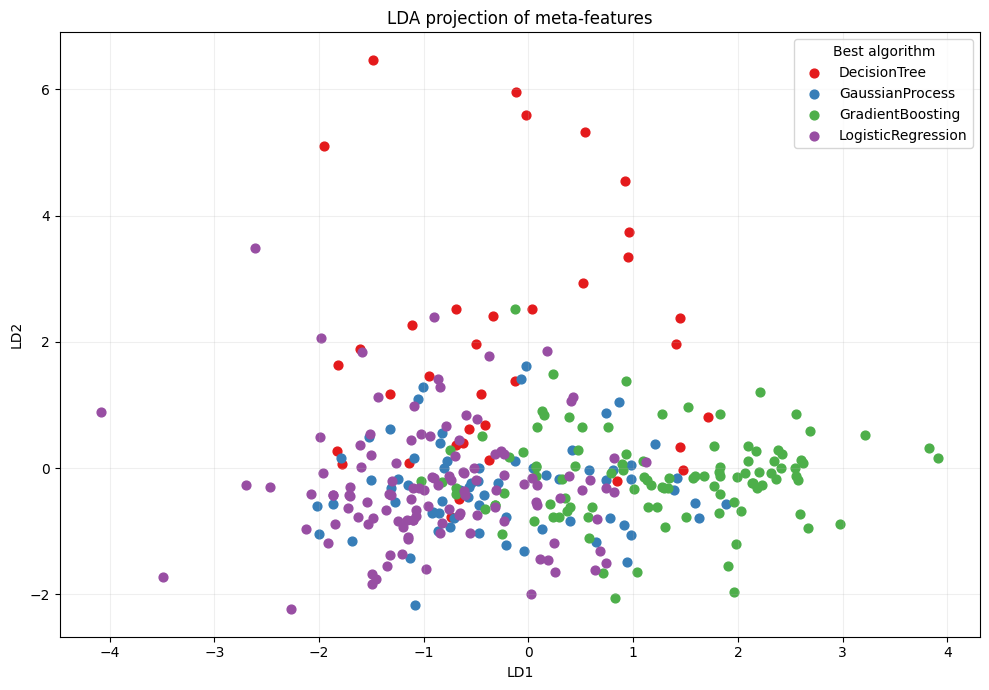

In [176]:
pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearDiscriminantAnalysis(n_components=2),
)

X_lda = pipeline.fit_transform(meta_x, meta_y)

plt.figure(figsize=(10, 7))

cmap = plt.get_cmap("Set1")

for i, label in enumerate(np.unique(meta_y)):
    mask = np.asarray(meta_y) == label

    plt.scatter(
        X_lda[mask, 0],
        X_lda[mask, 1],
        color=cmap(i),
        label=label,
        alpha=1.0,
        s=40,
    )

plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("LDA projection of meta-features")
plt.legend(title="Best algorithm")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

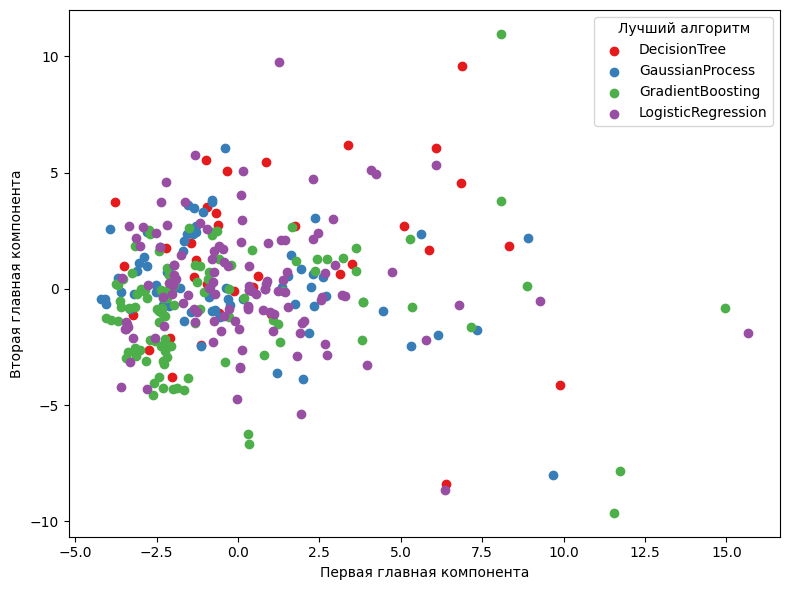

In [177]:
prepared = make_pipeline(
    SimpleImputer(strategy="median", keep_empty_features=True),
    StandardScaler(),
).fit_transform(meta_x.replace([np.inf, -np.inf], np.nan))

points = PCA(n_components=2).fit_transform(prepared)

plt.figure(figsize=(8, 6))

for i, label in enumerate(sorted(meta_y.unique())):
    mask = meta_y.to_numpy() == label
    plt.scatter(points[mask, 0], points[mask, 1], label=label, alpha=1.0, color=cmap(i))
    
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.legend(title="Лучший алгоритм")
plt.tight_layout()
plt.show()

In [178]:
manual_meta_results = evaluate_meta_models(meta_x, meta_y)
display(manual_meta_results)

,algorithm,f1_micro_mean,f1_micro_std
0,RandomForest,0.503003,0.010733
1,LogisticRegression,0.423742,0.049501
2,DecisionTree,0.417765,0.020414
3,Dummy,0.225716,0.068263


In [179]:
manual_second_level, _ = extract_manual_metafeatures(meta_x, meta_y)
display(manual_second_level)

{'n_obs': 328.0,
 'n_features': 59.0,
 'features_to_obs': 0.1798780487804878,
 'constant_features_ratio': 0.0,
 'binary_features_ratio': 0.0,
 'cardinality_mean': 202.42372881355934,
 'cardinality_std': 103.11277410052605,
 'relative_cardinality_mean': 0.6171455146754857,
 'relative_cardinality_std': 0.31436821372111606,
 'high_uniqueness_ratio': 0.06779661016949153,
 'categorical_features_ratio': 0.0,
 'categorical_entropy_mean': nan,
 'categorical_entropy_std': nan,
 'zero_ratio': 0.0,
 'zero_ratio_std': 0.0,
 'zero_ratio_max': 0.0,
 'n_classes': 4.0,
 'class_rate_min': 0.10975609756097561,
 'class_rate_max': 0.3597560975609756,
 'class_rate_std': 0.09860342456583066,
 'class_entropy': 1.8777464519798435,
 'median_abs_mean': 0.2752916700195962,
 'median_abs_max': 0.7207653479006042,
 'iqr_mean': 0.848410815047198,
 'iqr_std': 0.5526411921303247,
 'range_mean': 6.854335901759714,
 'range_max': 14.173987232981984,
 'skewness_abs_mean': 3.1142786136286382,
 'skewness_abs_std': 2.5207077

### Мета-набор на признаках PyMFE

In [180]:
def extract_pymfe_features(features, labels):
    mfe = MFE(
        groups=("general", "statistical", "model-based"),
        summary=("mean", "sd"),
        random_state=42,
        suppress_warnings=True,
    )
    features = features.reindex(sorted(features.columns, key=str), axis=1)
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        mfe.fit(features.to_numpy(), np.asarray(labels), rescale="standard", cat_cols="auto")
        names, values = mfe.extract(enable_parallel=True)
    return pd.Series(values, index=names, dtype=float)


In [181]:
variants = permutation_variants(x, y)

manual_comparison = {
    name: pd.Series(extract_manual_metafeatures(features, labels)[0])
    for name, (features, labels) in variants.items()
}

invariance = show_permutation_comparison(manual_comparison)

,исходный,строки,столбцы,категории
n_obs,148.000000,148.000000,148.000000,148.000000
n_features,18.000000,18.000000,18.000000,18.000000
features_to_obs,0.121622,0.121622,0.121622,0.121622
constant_features_ratio,0.000000,0.000000,0.000000,0.000000
binary_features_ratio,0.500000,0.500000,0.500000,0.500000
cardinality_mean,3.277778,3.277778,3.277778,3.277778
cardinality_std,1.850092,1.850092,1.850092,1.850092
relative_cardinality_mean,0.022147,0.022147,0.022147,0.022147
relative_cardinality_std,0.012501,0.012501,0.012501,0.012501
high_uniqueness_ratio,0.000000,0.000000,0.000000,0.000000


исходный     59
строки       59
столбцы      59
категории    59
Name: Совпадающих метапризнаков, dtype: int64

In [182]:
pymfe_rows = []
target_by_path = dict(zip(map(str, chosen_dataset), cols_with_target))
for path in tqdm(meta_df["path"], total=len(meta_df)):
    x, y = prepare_dataset(path, target_by_path[path])
    pymfe_rows.append(extract_pymfe_features(x, y))

pymfe_meta_df = pd.DataFrame(pymfe_rows).reset_index(drop=True)
pymfe_meta_df["best"] = meta_df["best"].to_numpy()
pymfe_x = pymfe_meta_df.drop(columns="best")
pymfe_y = pymfe_meta_df["best"]

pymfe_y.value_counts()


100%|██████████| 328/328 [00:58<00:00,  5.63it/s]


best
LogisticRegression    118
GradientBoosting      106
GaussianProcess        68
DecisionTree           36
Name: count, dtype: int64

In [183]:
pymfe_x

,attr_to_inst,can_cor.mean,can_cor.sd,cat_to_num,cor.mean,cor.sd,cov.mean,cov.sd,eigenvalues.mean,eigenvalues.sd,...,tree_depth.sd,tree_imbalance.mean,tree_imbalance.sd,tree_shape.mean,tree_shape.sd,var.mean,var.sd,var_importance.mean,var_importance.sd,w_lambda
0,0.042316,0.897717,0.105337,5.333333,NaN,NaN,8.293019e-02,1.138497e-01,0.982226,1.034354,...,2.086664,0.115528,0.120211,0.157629,0.132070,0.982226,1.375137e-01,0.018868,0.051675,8.240369e-09
1,0.121622,0.924706,0.080230,5.000000,1.326901e-01,1.305255e-01,1.335927e-01,1.314134e-01,1.006803,1.075995,...,1.640999,0.164807,0.108745,0.171224,0.101704,1.006803,2.450049e-15,0.030303,0.057968,1.671336e-07
2,0.592105,1.000000,NaN,NaN,9.034223e-02,1.220915e-01,9.154680e-02,1.237194e-01,1.013333,2.165625,...,1.394433,0.198257,0.112914,0.375000,0.125000,1.013333,1.550766e-15,0.005051,0.036819,0.000000e+00
3,0.050147,0.731098,NaN,NaN,1.091777e-01,1.270996e-01,1.095007e-01,1.274757e-01,1.002959,0.856126,...,2.841415,0.081597,0.114216,0.076193,0.070490,1.002959,4.634087e-15,0.038462,0.053459,4.654959e-01
4,0.042056,0.399631,NaN,0.000000,2.276984e-01,1.829921e-01,2.287674e-01,1.838512e-01,1.004695,0.875655,...,2.481857,0.102599,0.119817,0.125355,0.114988,1.004695,2.077037e-16,0.111111,0.097018,8.402948e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
323,0.021277,0.835555,NaN,0.000000,4.070565e-01,3.424769e-01,4.075383e-01,3.428822e-01,1.001183,2.256539,...,1.919245,0.133930,0.124341,0.146205,0.111764,1.001183,3.275794e-16,0.055556,0.088892,3.018473e-01
324,0.042056,0.399631,NaN,0.000000,2.276984e-01,1.829921e-01,2.287674e-01,1.838512e-01,1.004695,0.875655,...,2.481857,0.102599,0.119817,0.125355,0.114988,1.004695,4.710277e-16,0.111111,0.097018,8.402948e-01
325,0.006400,0.792164,NaN,0.000000,5.761673e-18,8.745102e-18,5.770906e-18,8.759116e-18,1.001603,0.000000,...,1.920541,0.108870,0.086987,0.051912,0.043814,1.001603,0.000000e+00,0.250000,0.020443,3.724757e-01
326,0.192982,NaN,NaN,1.750000,NaN,NaN,NaN,NaN,NaN,NaN,...,1.779328,0.159621,0.124603,0.244792,0.157006,NaN,NaN,0.011236,0.036882,NaN


/home/asphodel/Code/itmo-automl/.venv/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['g_mean.mean' 'g_mean.sd' 'h_mean.mean' 'h_mean.sd']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


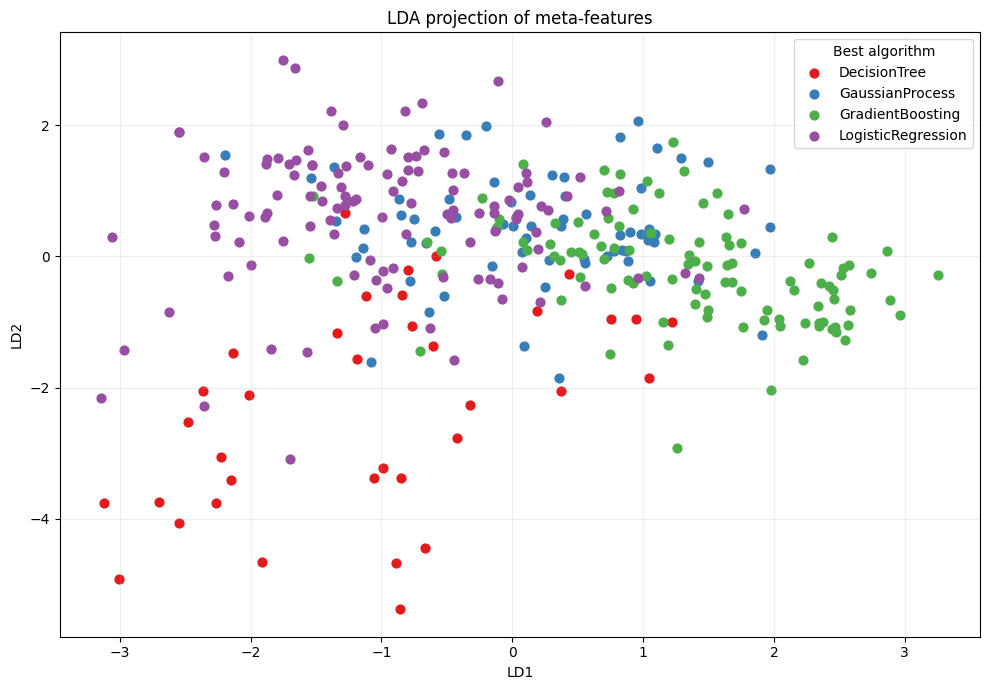

In [184]:
pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearDiscriminantAnalysis(n_components=2),
)

X_lda = pipeline.fit_transform(
    pymfe_x.replace([np.inf, -np.inf], np.nan),
    pymfe_y,
)

plt.figure(figsize=(10, 7))

cmap = plt.get_cmap("Set1")

for i, label in enumerate(np.unique(pymfe_y)):
    mask = np.asarray(pymfe_y) == label

    plt.scatter(
        X_lda[mask, 0],
        X_lda[mask, 1],
        color=cmap(i),
        label=label,
        alpha=1.0,
        s=40,
    )

plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("LDA projection of meta-features")
plt.legend(title="Best algorithm")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

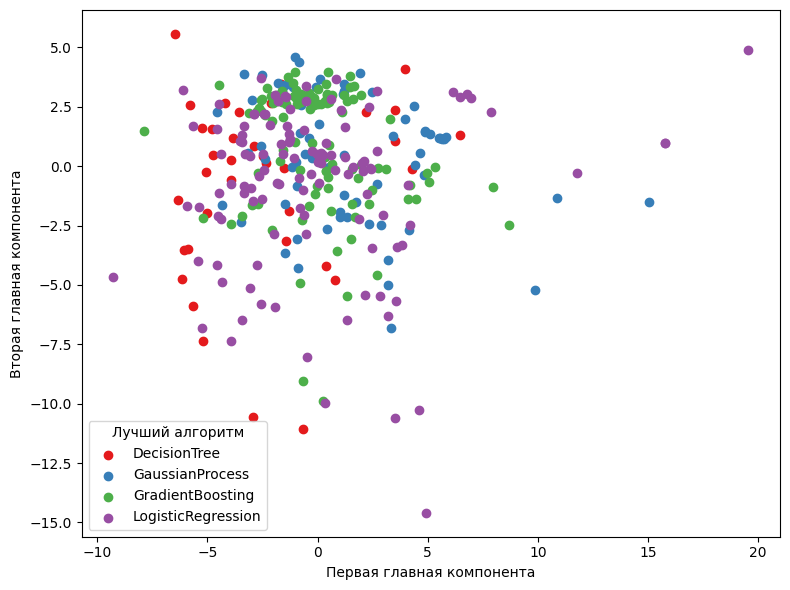

In [191]:
prepared = make_pipeline(
    SimpleImputer(strategy="median", keep_empty_features=True),
    StandardScaler(),
).fit_transform(pymfe_x.replace([np.inf, -np.inf], np.nan))

points = PCA(n_components=2).fit_transform(prepared)

plt.figure(figsize=(8, 6))

for i, label in enumerate(sorted(pymfe_y.unique())):
    mask = pymfe_y.to_numpy() == label
    plt.scatter(points[mask, 0], points[mask, 1], label=label, alpha=1.0, color=cmap(i))
    
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.legend(title="Лучший алгоритм")
plt.tight_layout()
plt.show()

In [192]:
pymfe_meta_results = evaluate_meta_models(pymfe_x, pymfe_y)
display(pymfe_meta_results)

,algorithm,f1_micro_mean,f1_micro_std
0,RandomForest,0.512177,0.005662
1,LogisticRegression,0.457075,0.059110
2,DecisionTree,0.390297,0.050250
3,Dummy,0.225716,0.068263


In [193]:
pymfe_prepared = pd.DataFrame(
    SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(
        pymfe_x.replace([np.inf, -np.inf], np.nan)
    ),
    columns=pymfe_x.columns,
)
pymfe_second_level = extract_pymfe_features(pymfe_prepared, pymfe_y)

pymfe_second_level.to_dict()


{'attr_to_inst': 0.25609756097560976,
 'can_cor.mean': 0.6440971354273201,
 'can_cor.sd': 0.059166151379247814,
 'cat_to_num': 0.0,
 'cor.mean': nan,
 'cor.sd': nan,
 'cov.mean': 0.14626209944842822,
 'cov.sd': 0.1776154963743753,
 'eigenvalues.mean': 0.9552934323576526,
 'eigenvalues.sd': 2.119520611013726,
 'freq_class.mean': 0.25,
 'freq_class.sd': 0.11385742743220259,
 'g_mean.mean': nan,
 'g_mean.sd': nan,
 'gravity': 3.1813126217003354,
 'h_mean.mean': nan,
 'h_mean.sd': nan,
 'inst_to_attr': 3.9047619047619047,
 'iq_range.mean': 0.6595342024920056,
 'iq_range.sd': 0.5148740378174037,
 'kurtosis.mean': nan,
 'kurtosis.sd': nan,
 'leaves': 78.0,
 'leaves_branch.mean': 7.602564102564102,
 'leaves_branch.sd': 2.0407519850948734,
 'leaves_corrob.mean': 0.01282051282051282,
 'leaves_corrob.sd': 0.01746462144073917,
 'leaves_homo.mean': 3981.0378066378066,
 'leaves_homo.sd': 5420.356598233877,
 'leaves_per_class.mean': 0.25,
 'leaves_per_class.sd': 0.024549413019393278,
 'lh_trace': 2.

In [201]:
def show_meta_feature_importance(features, labels, title, top_n=10):
    features = features.replace([np.inf, -np.inf], np.nan)
    x_train, x_test, y_train, y_test = train_test_split(
        features, labels,
        test_size=0.2,
        stratify=labels,
        random_state=42,
    )
    model = make_pipeline(
        SimpleImputer(strategy="median", keep_empty_features=True),
        RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
        ),
    )
    model.fit(x_train, y_train)
    baseline_f1 = f1_score(y_test, model.predict(x_test), average="micro")
    importance = permutation_importance(
        model, x_test, y_test,
        scoring="f1_micro",
        n_repeats=40,
        random_state=42,
        n_jobs=1,
    )
    ranking = pd.DataFrame({
        "мета-признак": features.columns,
        "важность": importance.importances_mean,
        "стандартное отклонение": importance.importances_std,
    }).sort_values("важность", ascending=False).reset_index(drop=True)

    print(f"{title}: F1-macro на отложенной выборке = {baseline_f1:.3f}")
    display(ranking.head(top_n))
    top = ranking.head(top_n).iloc[::-1]
    plt.figure(figsize=(9, max(5, 0.35 * len(top))))
    plt.barh(top["мета-признак"], top["важность"], xerr=top["стандартное отклонение"])
    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("Снижение F1-macro при перестановке признака")
    plt.title(title)
    plt.tight_layout()
    plt.show()
    
    return ranking

Ручные мета-признаки: F1-macro на отложенной выборке = 0.439


,мета-признак,важность,стандартное отклонение
0,relative_cardinality_std,0.020076,0.014918
1,kurtosis_abs_max,0.013258,0.010269
2,knn_nearest_distance_mean,0.008712,0.007490
3,tree_importance_entropy,0.007955,0.012210
4,tree_leaf_samples_std,0.007955,0.007566
5,high_uniqueness_ratio,0.007576,0.010164
6,cardinality_std,0.007576,0.015152
7,relative_cardinality_mean,0.005682,0.010545
8,class_entropy,0.005303,0.007227
9,skewness_abs_mean,0.004545,0.006943


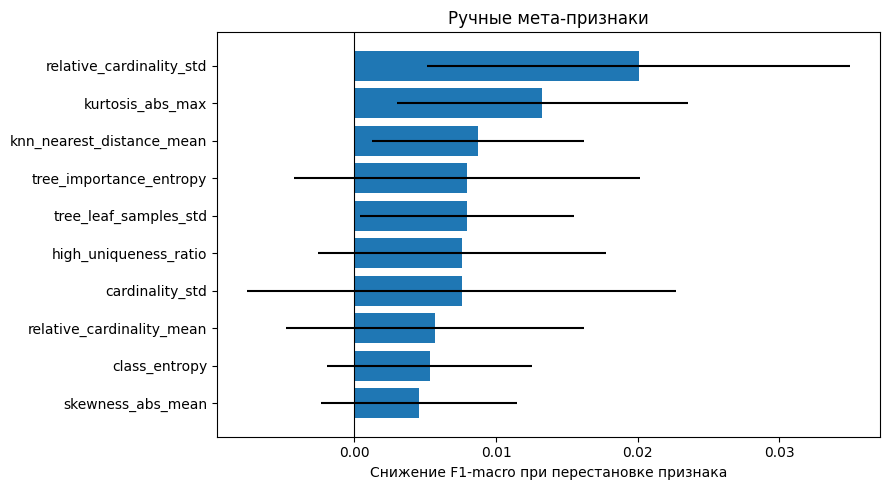

In [202]:
manual_feature_importance = show_meta_feature_importance(meta_x, meta_y, "Ручные мета-признаки")

Мета-признаки PyMFE: F1-macro на отложенной выборке = 0.424


,мета-признак,важность,стандартное отклонение
0,can_cor.mean,0.026515,0.012563
1,leaves_corrob.sd,0.024242,0.012121
2,nodes_per_inst,0.020076,0.015298
3,inst_to_attr,0.019697,0.013636
4,num_to_cat,0.015530,0.009870
5,nr_outliers,0.014773,0.010972
6,iq_range.sd,0.014394,0.008264
7,tree_depth.mean,0.010985,0.012210
8,tree_shape.sd,0.010985,0.006765
9,lh_trace,0.009848,0.010470


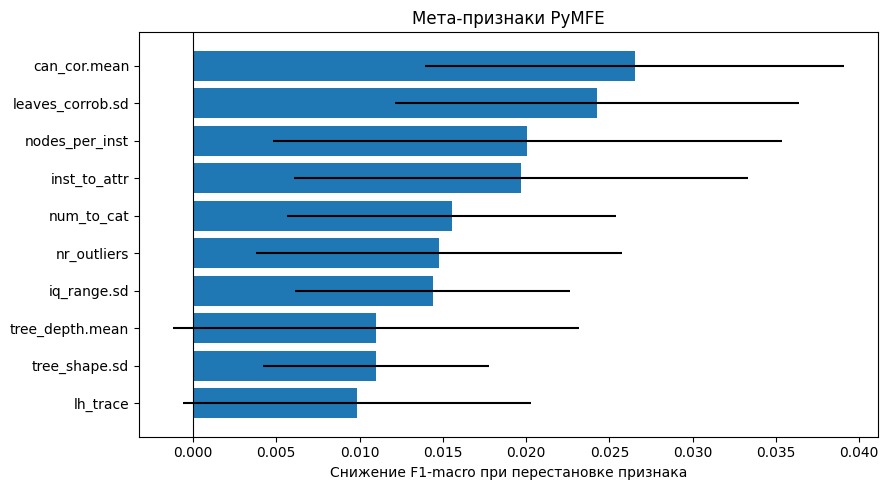

In [203]:
pymfe_feature_importance = show_meta_feature_importance(pymfe_x, pymfe_y, "Мета-признаки PyMFE")

In [197]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer

X = meta_x.replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)

importance = mutual_info_classif(
    X,
    meta_y,
    random_state=42,
)

mi_importance = pd.Series(
    importance,
    index=meta_x.columns,
).sort_values(ascending=False)

display(mi_importance.head(20))

high_uniqueness_ratio          0.184386
kurtosis_mean                  0.162356
relative_cardinality_mean      0.141859
iqr_mean                       0.137874
cardinality_mean               0.136888
tree_nodes                     0.136344
knn_mean_distance_std          0.129928
tree_leaves                    0.125357
relative_cardinality_std       0.121940
knn_neighbor_agreement_mean    0.119939
kurtosis_abs_max               0.119715
tree_used_features_ratio       0.116216
knn_nearest_distance_std       0.114179
knn_mean_distance_mean         0.112403
knn_nearest_distance_max       0.111780
n_features                     0.111313
correlation_mean               0.110640
tree_leaf_samples_mean         0.106939
median_abs_max                 0.105106
outlier_ratio_mean             0.101738
dtype: float64